# Breast Cancer Classification with Logistic Regression

Predicting whether a tumor is benign or malignant using the Breast Cancer Wisconsin dataset.

In [1]:
import os
import pandas as pd

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Dataset source: Kaggle

In [4]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Dataset downloaded to: /kaggle/input/breast-cancer-wisconsin-data


In [5]:

for file in os.listdir(path):
  print(file)

data.csv


In [6]:
import glob
csv_files = glob.glob(os.path.join(path, '*.csv'))
print(csv_files)

['/kaggle/input/breast-cancer-wisconsin-data/data.csv']


## Data inspection and cleaning

In [7]:
df = pd.read_csv(csv_files[0])
df.head(5)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [8]:
df.groupby('diagnosis')['id'].count()

,id
diagnosis,
B,357
M,212


In [9]:
df.shape

(569, 33)

In [10]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [11]:
df.dropna(axis=1, inplace=True)

In [12]:
df.isna().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [13]:
df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


In [14]:
df.dtypes

,0
id,int64
diagnosis,object
radius_mean,float64
texture_mean,float64
perimeter_mean,float64
area_mean,float64
smoothness_mean,float64
compactness_mean,float64
concavity_mean,float64
concave points_mean,float64


In [15]:
# Benign = 0, Malignant = 1

In [16]:
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

In [17]:
df['diagnosis']

,diagnosis
0,1
1,1
2,1
3,1
4,1
...,...
564,1
565,1
566,1
567,1


In [18]:
x = df.iloc[:, 2:].values
y = df.iloc[:, 1].values

In [19]:
from sklearn.model_selection import train_test_split

## Train and evaluate the model

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0, stratify=y)

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
classifier = LogisticRegression(max_iter=1000, random_state=0)

In [28]:
# y_train = y_train.astype(int)
# y_test = y_test.astype(int)
classifier.fit(x_train, y_train)

LogisticRegression(max_iter=1000, random_state=0)

In [29]:
pred = classifier.predict(x_test)

In [30]:
from sklearn.metrics import confusion_matrix

In [31]:
cm = confusion_matrix(y_test, pred)

In [32]:
cm

array([[71,  1],
       [ 2, 40]])

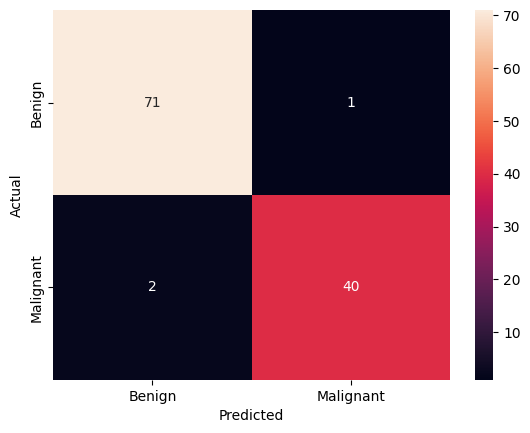

In [34]:
sns.heatmap(cm, annot=True, fmt="d",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [35]:
from sklearn.metrics import accuracy_score

In [36]:
accuracy_score(y_test, pred)

0.9736842105263158

In [37]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))
print("ROC-AUC:", roc_auc_score(y_test, classifier.predict_proba(x_test)[:, 1]))

              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

ROC-AUC: 0.9933862433862434
